# Semana 12 — Ajuste de modelos y generalización

**Objetivo:** comparar modelos por su error en datos **no usados** para ajustarlos, y ver por qué
el error de entrenamiento engaña.

## Modelo y método

Datos sintéticos con una relación cuadrática conocida:

$$y = 1 + 0.8x + 0.5x^2 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.3^2)$$

Se ajustan por mínimos cuadrados polinomios de grado $d = 1, \dots, 8$:

$$\hat{\boldsymbol\beta} = \arg\min_{\boldsymbol\beta} \sum_{i \in \text{train}} \big(y_i - \textstyle\sum_{p=0}^{d} \beta_p x_i^p\big)^2$$

y se mide el error en un conjunto reservado:
$\text{RMSE}_\text{test} = \sqrt{\frac{1}{n_\text{test}}\sum_{i \in \text{test}}(y_i - \hat y_i)^2}$.

**Lo esperado:** el error de entrenamiento baja siempre al subir el grado; el de prueba baja
hasta el grado verdadero (2) y luego deja de mejorar o empeora (sobreajuste). Ningún modelo puede
bajar del ruido irreducible $\sigma = 0.3$ en promedio.

Partición: 30 % de los puntos se reservan al azar (semilla 12) y no se tocan durante el ajuste.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import fit_linear_model
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 12
NOISE_SD = 0.3
rng = np.random.default_rng(12)
x = np.linspace(-2.0, 2.0, 60)
y = 1.0 + 0.8 * x + 0.5 * x**2 + rng.normal(0.0, NOISE_SD, x.size)
order = rng.permutation(x.size)
train, test = np.sort(order[:42]), np.sort(order[42:])


def features(values: np.ndarray, degree: int) -> np.ndarray:
    return np.column_stack([values**power for power in range(1, degree + 1)])


def rmse(observed: np.ndarray, predicted: np.ndarray) -> float:
    return float(np.sqrt(np.mean((observed - predicted) ** 2)))


degrees = np.arange(1, 9)
models = {degree: fit_linear_model(features(x[train], degree), y[train]) for degree in degrees}
train_rmse = np.array([rmse(y[train], models[d].predict(features(x[train], d))) for d in degrees])
test_rmse = np.array([rmse(y[test], models[d].predict(features(x[test], d))) for d in degrees])

## Figura

Izquierda: datos y tres ajustes (grado 1, 2 y 8). Derecha: RMSE de entrenamiento y de prueba
frente al grado; la línea gris es el ruido verdadero.

Saved: weeks/week_12_model_generalization/outputs/model_generalization.png
Saved: weeks/week_12_model_generalization/outputs/model_generalization.npz


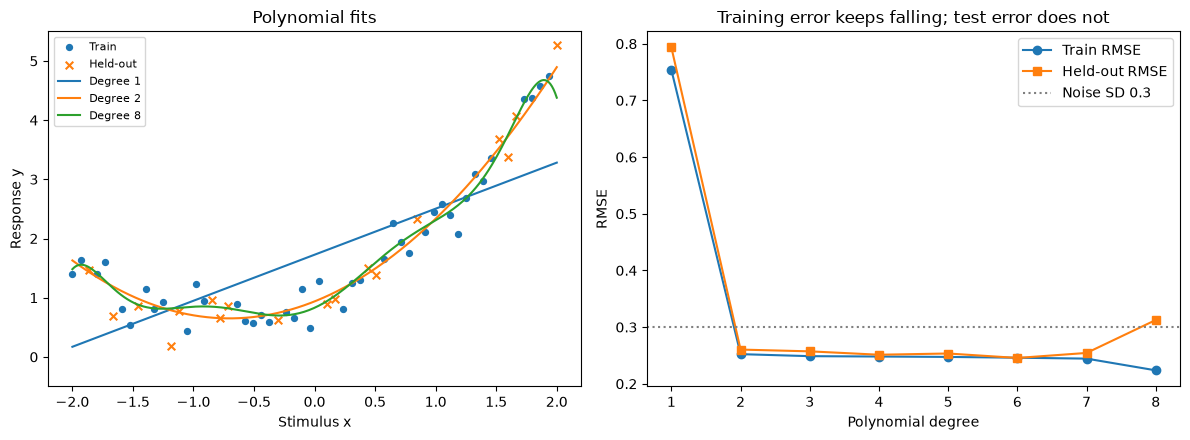

In [2]:
grid = np.linspace(-2.0, 2.0, 300)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(x[train], y[train], s=18, label="Train")
axes[0].scatter(x[test], y[test], s=30, marker="x", label="Held-out")
for degree in (1, 2, 8):
    axes[0].plot(grid, models[degree].predict(features(grid, degree)), label=f"Degree {degree}")
axes[0].set(xlabel="Stimulus x", ylabel="Response y", ylim=(-0.5, 5.5), title="Polynomial fits")
axes[0].legend(fontsize=8)
axes[1].plot(degrees, train_rmse, "o-", label="Train RMSE")
axes[1].plot(degrees, test_rmse, "s-", label="Held-out RMSE")
axes[1].axhline(NOISE_SD, color="grey", linestyle=":", label=f"Noise SD {NOISE_SD}")
axes[1].set(xlabel="Polynomial degree", ylabel="RMSE", title="Training error keeps falling; test error does not")
axes[1].legend()
save_figure(WEEK, figure, "model_generalization.png")
save_data(WEEK, "model_generalization.npz", degrees=degrees, train_rmse=train_rmse, test_rmse=test_rmse,
          train_indices=train, test_indices=test)

## Validación

- El RMSE de entrenamiento no aumenta con el grado (modelos anidados).
- El cuadrático mejora claramente al lineal en datos de prueba.
- El mejor RMSE de prueba está cerca del ruido verdadero (0.3).
- El modelo cuadrático recupera los coeficientes verdaderos (1, 0.8, 0.5).

In [3]:
assert np.all(np.diff(train_rmse) <= 1e-9)
assert test_rmse[1] < 0.6 * test_rmse[0]
assert abs(test_rmse.min() - NOISE_SD) < 0.1
quadratic = models[2]
assert np.allclose([quadratic.intercept, *quadratic.coefficients], [1.0, 0.8, 0.5], atol=0.2)
print("Held-out RMSE by degree:", dict(zip(degrees.tolist(), test_rmse.round(3).tolist())))
print(f"Quadratic coefficients: intercept {quadratic.intercept:.2f}, {np.round(quadratic.coefficients, 2)}")

Held-out RMSE by degree: {1: 0.793, 2: 0.26, 3: 0.257, 4: 0.251, 5: 0.253, 6: 0.246, 7: 0.254, 8: 0.313}
Quadratic coefficients: intercept 0.94, [0.82 0.58]


## Interpretación y límites

- Elegir el grado con el error de entrenamiento siempre favorece el modelo más complejo.
- Una sola partición es ruidosa: con pocos datos, validación cruzada (semana 14) da una
  estimación más estable.
- Si el conjunto de prueba se usa para elegir el grado, ya no es una estimación independiente:
  haría falta un tercer conjunto o validación cruzada anidada.

**Para tu entrega:** repite con otras 10 semillas y reporta qué grado gana cada vez.